# Model of a "normal" day 

This notebook answers four points, in this order:

1. **The model**: equation and justification, fitted at city level (and per cell if the cell file is available).
2. **Why a negative binomial**: variance-vs-mean plot.
3. **The anomaly score**: how surprising is an observed count given the expected one (Pearson residual and NB p-value, both directions).
4. **Multiple testing**: Benjamini–Hochberg across all tests.

Weather is **not** in this model (out of scope for now). So "anomalies" here mean *what the calendar and the level of the year do not explain*, and cold or stormy days will show up as anomalies. This is the "no weather" model.

## 0. Setup

In [2]:
%pip install pyarrow

Note: you may need to restart the kernel to use updated packages.


In [1]:
CITY_PATH  = "data/daily_counts_city.csv"        # columns: date, n_trips
CELLS_PATH = "data/daily_counts_cells.parquet"   # one row per day x cell (columns detected below)
START, END = "2022-01-01", "2025-12-31"          # study period
N_HARMONICS   = 3       # smoothness of the annual cycle (Fourier terms)
Z_CLIP        = 3.0     # robust refit: days with |residual| > Z_CLIP are left out of the fit
ROBUST_ROUNDS = 2
USE_CELL_INTERACTIONS = False   # cell x weekend and cell x season (slower; see section 1.4)
RAW_ALPHA = 0.01        # raw p-value threshold used to show the false-alarm problem (section 4)
Q_FDR     = 0.05        # Benjamini-Hochberg: accepted share of false alarms among flagged cell-days

In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests

try:
    import holidays
except ImportError:
    %pip install holidays
    import holidays
%matplotlib inline
pd.set_option("display.width", 160)

### 0.1 Calendar
`holidays.US(state="IL")` gives the hollyday dtes. We keep the holidays that change riding (New Year, Memorial Day, July 4, Labor Day, Thanksgiving, Christmas), give **Christmas its own flag** (it is far quieter than the others), and add bridge days and Chicago Public Schools breaks by hand.

In [4]:
MAJOR_KEYWORDS = ("New Year", "Memorial", "Independence", "Labor", "Thanksgiving", "Christmas")

def build_calendar(start=START, end=END):
    cal = pd.DataFrame({"date": pd.date_range(start, end, freq="D")})
    il = holidays.US(state="IL", years=range(cal.date.dt.year.min(), cal.date.dt.year.max() + 1))
    d = cal.date.dt.date
    cal["is_holiday"] = d.isin(il)
    cal["holiday_name"] = d.map(il).fillna("")
    # "Independence" also matches Juneteenth National Independence Day -> excluded on purpose
    cal["is_major_holiday"] = cal.holiday_name.apply(lambda n: any(k in n for k in MAJOR_KEYWORDS) and "Juneteenth" not in n)
    return cal

# Chicago Public Schools breaks (first day off, last day off)
SCHOOL_BREAKS = {
    "winter": [("2021-12-20", "2022-01-02"), ("2022-12-23", "2023-01-06"), ("2023-12-22", "2024-01-07"),
               ("2024-12-23", "2025-01-03"), ("2025-12-22", "2026-01-02")],
    "spring": [("2022-04-11", "2022-04-15"), ("2023-04-03", "2023-04-07"),
               ("2024-03-25", "2024-03-29"), ("2025-03-24", "2025-03-28")],
}

def add_school_breaks(cal):
    cal = cal.copy()
    for name, periods in SCHOOL_BREAKS.items():
        cal[f"is_{name}_break"] = False
        for s, e in periods:
            cal.loc[(cal.date >= s) & (cal.date <= e), f"is_{name}_break"] = True
    return cal

def add_holiday_context(cal):
    """Bridge days: eve of a holiday, long weekends, Thanksgiving week, Christmas."""
    cal = cal.copy().sort_values("date").reset_index(drop=True)
    is_off = cal.is_major_holiday | (cal.date.dt.dayofweek >= 5)
    block = (is_off != is_off.shift()).cumsum()
    block_len = is_off.groupby(block).transform("sum")
    has_hol = cal.is_major_holiday.groupby(block).transform("any")
    cal["is_long_weekend"] = is_off & (block_len >= 3) & has_hol & ~cal.is_major_holiday
    cal["is_holiday_eve"] = cal.is_major_holiday.shift(-1, fill_value=False) & ~is_off
    tg = cal.loc[cal.holiday_name.str.contains("Thanksgiving") & ~cal.holiday_name.str.contains("After"), "date"]
    week_starts = set(tg - pd.to_timedelta(tg.dt.dayofweek, unit="D"))
    cal["is_thanksgiving_week"] = (cal.date - pd.to_timedelta(cal.date.dt.dayofweek, unit="D")).isin(week_starts)
    cal["is_christmas"] = cal.holiday_name.str.contains("Christmas")
    return cal

calendar_df = add_holiday_context(add_school_breaks(build_calendar()))
FLAGS = ["is_major_holiday", "is_christmas", "is_holiday_eve", "is_long_weekend",
         "is_thanksgiving_week", "is_winter_break", "is_spring_break"]
calendar_df.assign(year=calendar_df.date.dt.year).groupby("year")[FLAGS].sum()
calendar_df.to_csv("data/calendar.csv", index=False)

### 0.2 Features shared by the city and cell models
Day of week, smooth annual cycle (Fourier), a weekend x season interaction (the commuter/leisure mix changes through the year), and the year.

In [5]:
def add_features(df):
    df = df.copy()
    df["dow"] = df.date.dt.day_name() #day of week
    df["is_weekend"] = (df.date.dt.dayofweek >= 5).astype(int)
    df["year"] = df.date.dt.year.astype(str)
    doy = df.date.dt.dayofyear
    for k in range(1, N_HARMONICS + 1):
        df[f"sin{k}"] = np.sin(2 * np.pi * k * doy / 365.25)
        df[f"cos{k}"] = np.cos(2 * np.pi * k * doy / 365.25)
    df["wkend_sin1"] = df.is_weekend * df.sin1
    df["wkend_cos1"] = df.is_weekend * df.cos1
    return df

HARM = [f"{f}{k}" for k in range(1, N_HARMONICS + 1) for f in ("sin", "cos")]
CAL_TERMS = ["C(dow)", "wkend_sin1", "wkend_cos1"] + HARM + FLAGS + ["C(year)"]

# ---- city data ----
city = pd.read_csv(CITY_PATH, parse_dates=["date"])
city = city[(city.date >= START) & (city.date <= END)]
city = add_features(city.merge(calendar_df, on="date", how="left")).sort_values("date").reset_index(drop=True)
missing = pd.date_range(START, END).difference(city.date)
print(f"City: {len(city)} days, {len(missing)} days without data", [str(m.date()) for m in missing[:10]])

City: 1461 days, 0 days without data []


## Why those params



In [8]:
import matplotlib.ticker as mticker
INK, INK2, MUTED, GRID = "#1a1a1a", "#4d4d4d", "#8a8a8a", "#e4e3df"
BLUE, ORANGE = "#2f6db5", "#d98324"
YEAR_COLORS = {"2022": "#bcd2ea", "2023": "#7fa8d4", "2024": "#3f78b8", "2025": "#123f78"}
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
 
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .8, "axes.axisbelow": True,
    "figure.facecolor": "white", "axes.facecolor": "white", "font.size": 10,
})
 
eda = city.copy()
eda["month"] = eda.date.dt.month
eda["dow_n"] = eda.date.dt.dayofweek        # 0 = Monday
 
 
def local_reference(df, excluded, window=28, min_days=3):
    """For each day: median trips of the SAME weekday within +-window days,
    using only ordinary days (no holiday / break / bridge flag). Data only, no model.
    ratio = trips / reference  ->  1.0 means 'as usual for that weekday at that time of year'."""
    t = (df.date - df.date.min()).dt.days.values
    dow = df.dow_n.values
    y = df.n_trips.values.astype(float)
    ok = ~excluded.values
    ref = np.full(len(df), np.nan)
    for i in range(len(df)):
        m = ok & (dow == dow[i]) & (np.abs(t - t[i]) <= window) & (np.arange(len(df)) != i)
        if m.sum() >= min_days:
            ref[i] = np.median(y[m])
    return ref
 
 
any_flag = eda[FLAGS].any(axis=1)
eda["ref"] = local_reference(eda, any_flag)
eda["ratio"] = eda.n_trips / eda.ref
print(f"{eda.ratio.notna().sum()} days have a local reference; "
      f"{int(any_flag.sum())} flagged days are compared with ordinary days of the same weekday nearby.")
 
 
def strip_by_group(ax, groups, color=BLUE):
    """One row per group: every day as a dot (ratio to usual), median as a vertical tick, n and median on the right."""
    rng = np.random.default_rng(0)
    for i, (label, r) in enumerate(groups[::-1]):
        r = r.dropna()
        ax.scatter(r, i + rng.uniform(-.17, .17, len(r)), s=16, color=color, alpha=.55, linewidth=0, zorder=3)
        if len(r):
            med = r.median()
            ax.plot([med, med], [i - .3, i + .3], color=INK, lw=2.2, zorder=4)
            ax.text(1.03, i, f"median {med:.2f}  (n={len(r)})", transform=ax.get_yaxis_transform(),
                    va="center", fontsize=9, color=INK2)
    ax.axvline(1, color=INK2, lw=1, zorder=2)
    ax.set_yticks(range(len(groups))); ax.set_yticklabels([g[0] for g in groups[::-1]])
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(mticker.FixedLocator([.2, .3, .5, .7, 1, 1.5, 2]))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.grid(axis="y", visible=False)

1461 days have a local reference; 139 flagged days are compared with ordinary days of the same weekday nearby.


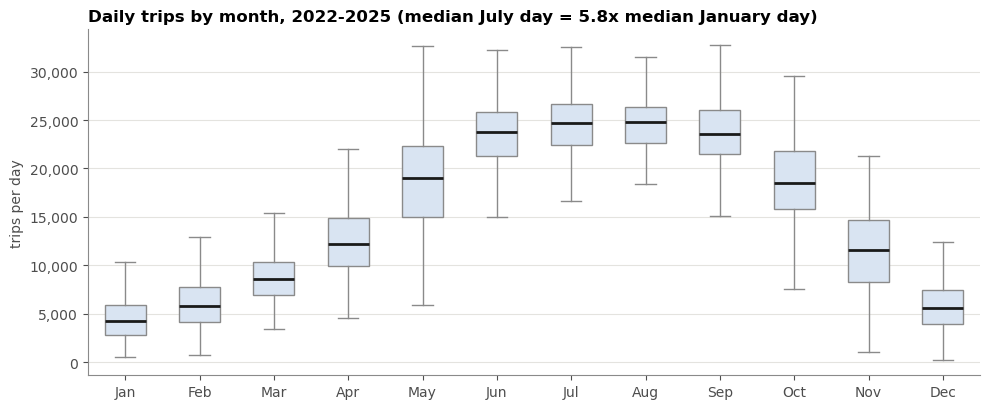

What to look for: one smooth hump with no jump from one month to the next -> a smooth annual wave (sin/cos) fits better than 12 separate steps.


In [10]:

# ======== CELL H1  (why a smooth SEASON)
fig, ax = plt.subplots(figsize=(10, 4.2))
data = [eda.loc[eda.month == m, "n_trips"].values for m in range(1, 13)]
bp = ax.boxplot(data, widths=.55, patch_artist=True, showfliers=False,
                medianprops=dict(color=INK, lw=2), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                boxprops=dict(edgecolor=MUTED))
for b in bp["boxes"]:
    b.set_facecolor("#d9e4f2")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(MONTHS)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_ylabel("trips per day"); ax.grid(axis="x", visible=False)
jan, jul = np.median(data[0]), np.median(data[6])
ax.set_title(f"Daily trips by month, 2022-2025 (median July day = {jul / jan:.1f}x median January day)")
plt.tight_layout(); plt.show()
print("What to look for: one smooth hump with no jump from one month to the next -> a smooth annual wave (sin/cos) fits better than 12 separate steps.")
 

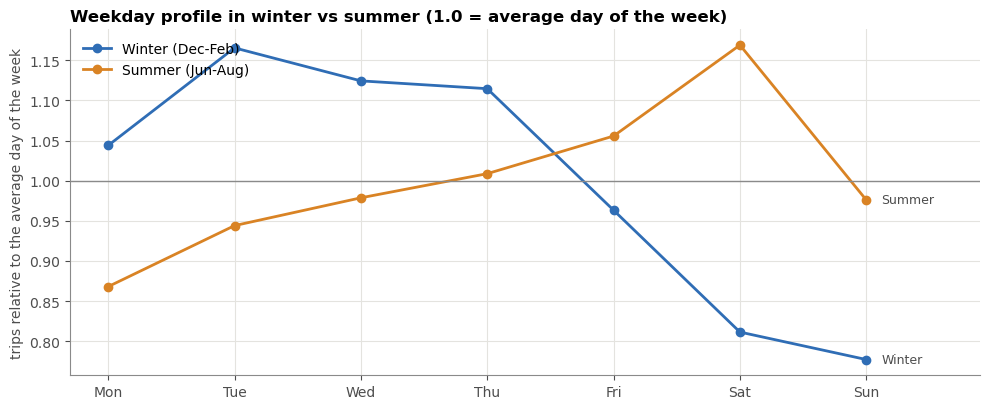

What to look for: do weekdays differ (-> weekday terms)? Do the winter and summer lines have different shapes (-> a weekend x season interaction is worth having)? If the two lines were parallel, it would not be.


In [11]:
# ======== CELL H2  (why WEEKDAY, and why weekend x season)
prof = {}
for name, months in {"Winter (Dec-Feb)": [12, 1, 2], "Summer (Jun-Aug)": [6, 7, 8]}.items():
    sub = eda[eda.month.isin(months) & ~any_flag]
    g = sub.groupby("dow_n").n_trips.mean()
    prof[name] = g / g.mean()                      # 1.0 = average day of that season's week
fig, ax = plt.subplots(figsize=(10, 4.2))
cols = {"Winter (Dec-Feb)": BLUE, "Summer (Jun-Aug)": ORANGE}
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
for name, s in prof.items():
    ax.plot(range(7), s.values, marker="o", ms=6, lw=2, color=cols[name], label=name)
    ax.text(6.12, s.values[-1], name.split(" ")[0], color=INK2, va="center", fontsize=9)
ax.axhline(1, color=MUTED, lw=1)
ax.set_xticks(range(7)); ax.set_xticklabels(days); ax.set_xlim(-.3, 6.9)
ax.set_ylabel("trips relative to the average day of the week")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Weekday profile in winter vs summer (1.0 = average day of the week)")
plt.tight_layout(); plt.show()
print("What to look for: do weekdays differ (-> weekday terms)? Do the winter and summer lines have different shapes "
      "(-> a weekend x season interaction is worth having)? If the two lines were parallel, it would not be.")

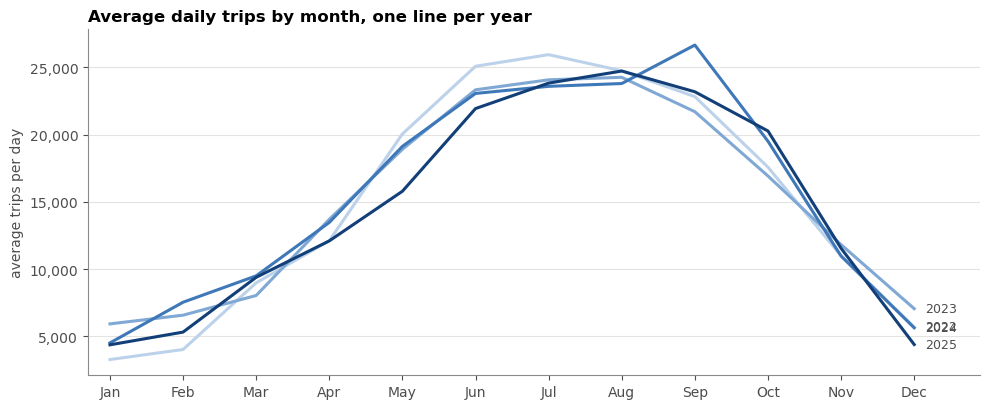

      level vs first year
year                     
2022                1.000
2023                1.004
2024                1.030
2025                0.975
What to look for: lines with the same shape but at different heights -> one multiplier per year is enough.


In [12]:
# ======== CELL H3  (why a YEAR effect)
fig, ax = plt.subplots(figsize=(10, 4.2))
mm = eda.groupby(["year", "month"]).n_trips.mean().unstack(0)
for yr in mm.columns:
    ax.plot(mm.index, mm[yr], lw=2.2, color=YEAR_COLORS.get(str(yr), MUTED))
    ax.text(12.15, mm[yr].iloc[-1], str(yr), color=INK2, va="center", fontsize=9)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(MONTHS); ax.set_xlim(.7, 12.9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_ylabel("average trips per day"); ax.grid(axis="x", visible=False)
ax.set_title("Average daily trips by month, one line per year")
plt.tight_layout(); plt.show()
yr_mean = eda.groupby("year").n_trips.mean()
print((yr_mean / yr_mean.iloc[0]).round(3).to_frame("level vs first year"))
print("What to look for: lines with the same shape but at different heights -> one multiplier per year is enough.")
 

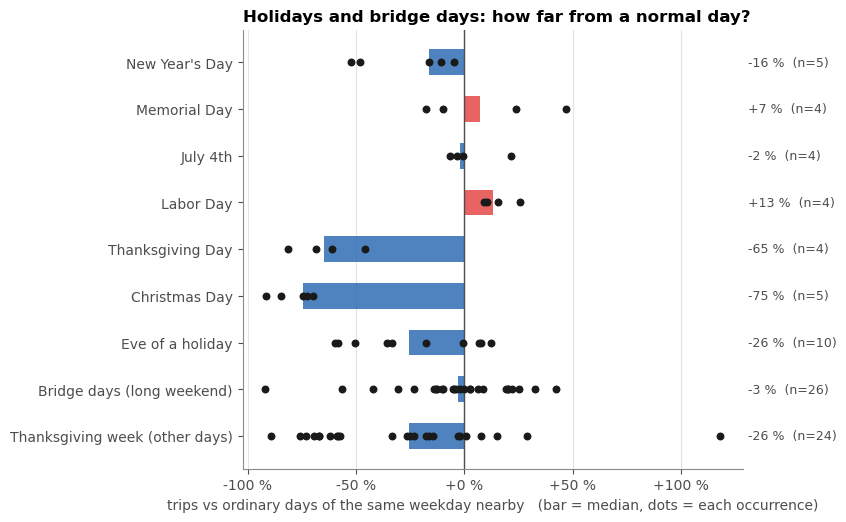

What to look for: bars far from 0 with dots on the same side = a real calendar effect. Dots on both sides of 0 = no consistent effect. A very different Christmas bar -> its own flag.


In [15]:
# ======== CELL H4  (why HOLIDAYS and bridge days)
# Bars = median % difference vs ordinary days of the same weekday nearby; dots = each individual occurrence (one per year).
name = eda.holiday_name.fillna("")
groups = [
    ("New Year's Day",            eda.is_major_holiday & name.str.contains("New Year")),
    ("Memorial Day",              eda.is_major_holiday & name.str.contains("Memorial")),
    ("July 4th",                  eda.is_major_holiday & name.str.contains("Independence")),
    ("Labor Day",                 eda.is_major_holiday & name.str.contains("Labor")),
    ("Thanksgiving Day",          eda.is_major_holiday & name.str.contains("Thanksgiving") & ~name.str.contains("After")),
    ("Day after Thanksgiving",    eda.is_major_holiday & name.str.contains("After")),
    ("Christmas Day",             eda.is_christmas),
    ("Eve of a holiday",          eda.is_holiday_eve),
    ("Bridge days (long weekend)", eda.is_long_weekend),
    ("Thanksgiving week (other days)", eda.is_thanksgiving_week & ~eda.is_major_holiday),
]
rows = []
for label, mask in groups:
    r = ((eda.loc[mask, "ratio"] - 1) * 100).dropna()
    if len(r):
        rows.append((label, r))
fig, ax = plt.subplots(figsize=(10, 0.5 * len(rows) + 1.6))
ypos = np.arange(len(rows))[::-1]
for y, (label, r) in zip(ypos, rows):
    med = r.median()
    ax.barh(y, med, height=.55, color=(BLUE if med < 0 else "#e34948"), alpha=.85, zorder=2)
    ax.scatter(r, np.full(len(r), y), s=22, color=INK, zorder=4)
    ax.text(1.01, y, f"{med:+.0f} %  (n={len(r)})", transform=ax.get_yaxis_transform(), va="center", fontsize=9, color=INK2)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(ypos); ax.set_yticklabels([r[0] for r in rows])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:+.0f} %"))
ax.grid(axis="y", visible=False)
ax.set_xlabel("trips vs ordinary days of the same weekday nearby   (bar = median, dots = each occurrence)")
ax.set_title("Holidays and bridge days: how far from a normal day?")
plt.subplots_adjust(right=.78, left=.28, bottom=.16); plt.show()
print("What to look for: bars far from 0 with dots on the same side = a real calendar effect. "
      "Dots on both sides of 0 = no consistent effect. A very different Christmas bar -> its own flag.")

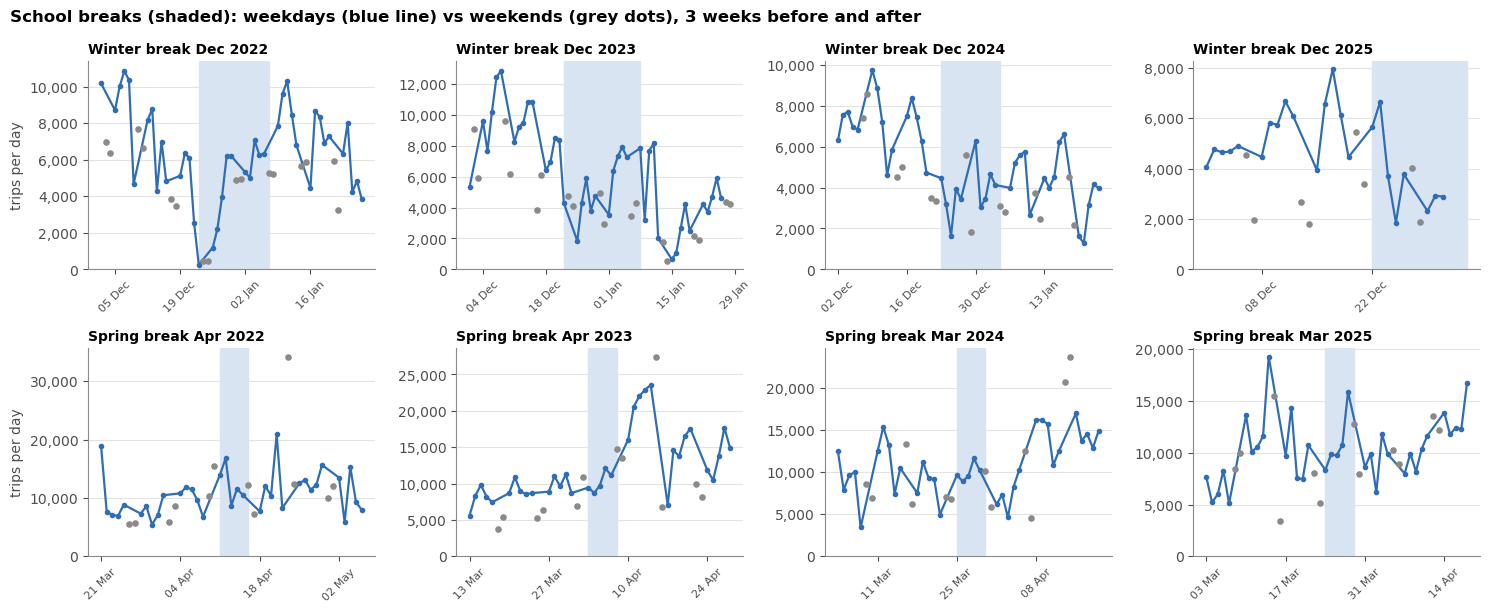

What to look for: during the shaded band, does the blue weekday line move toward the weekend dots or drop below the weeks around it? If yes, the school calendar matters. Winter breaks also contain Christmas and New Year, so look at spring break (second row) for the cleanest signal.


In [16]:
# ======== CELL H5  (why SCHOOL BREAKS)
# One panel per break: daily trips around the break, break shaded. Weekdays joined by a line, weekends as grey dots.
def break_panels(kind, pad=21):
    periods = []
    for a, b in SCHOOL_BREAKS[kind]:
        a, b = pd.Timestamp(a), pd.Timestamp(b)
        inside = eda[(eda.date >= a) & (eda.date <= b)]
        if len(inside) >= 3:                       # skip breaks that fall (almost) outside the study period
            periods.append((a, b))
    return periods
 
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2))
for r, kind in enumerate(["winter", "spring"]):
    per = break_panels(kind)
    ymax = 0
    for c in range(4):
        ax = axes[r, c]
        if c >= len(per):
            ax.axis("off"); continue
        a, b = per[c]
        w = eda[(eda.date >= a - pd.Timedelta(days=21)) & (eda.date <= b + pd.Timedelta(days=21))]
        wd, we = w[w.dow_n < 5], w[w.dow_n >= 5]
        ax.axvspan(a, b + pd.Timedelta(days=1), color="#d9e4f2", zorder=1)
        ax.plot(wd.date, wd.n_trips, color=BLUE, lw=1.6, marker="o", ms=3, zorder=3)
        ax.scatter(we.date, we.n_trips, s=14, color=MUTED, zorder=3)
        ax.set_title(f"{kind.capitalize()} break {a:%b %Y}", fontsize=10)
        ax.xaxis.set_major_locator(plt.matplotlib.dates.WeekdayLocator(byweekday=0, interval=2))
        ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
        ax.tick_params(axis="x", labelrotation=45, labelsize=8)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
        ax.set_ylim(bottom=0); ax.grid(axis="x", visible=False)
        if c == 0:
            ax.set_ylabel("trips per day")
fig.suptitle("School breaks (shaded): weekdays (blue line) vs weekends (grey dots), 3 weeks before and after", x=.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
print("What to look for: during the shaded band, does the blue weekday line move toward the weekend dots "
      "or drop below the weeks around it? If yes, the school calendar matters. Winter breaks also contain Christmas and "
      "New Year, so look at spring break (second row) for the cleanest signal.")

## 1. The model

For cell $c$ on day $t$ (at city level there is a single series, so no cell term):

$$y_{c,t} \sim \mathrm{NegBin}(\mu_{c,t},\ \alpha), \qquad \mathrm{Var}(y_{c,t}) = \mu_{c,t} + \alpha\,\mu_{c,t}^2$$

$$\log \mu_{c,t} = \underbrace{\beta_c}_{\text{cell level}} + \underbrace{\gamma_{\text{weekday}(t)}}_{\text{weekday}} + \underbrace{f\big(\text{day of year}(t)\big)}_{\text{season (smooth)}} + \underbrace{\delta^\top h_t}_{\text{holidays, bridge days, school breaks}} + \underbrace{\theta_{\text{year}(t)}}_{\text{year effect}}$$

**Why this model**
- **Counts and the log link.** Trips are non-negative integers, and effects such as weekday, season or holiday act as multipliers, so we model $\log\mu$ as a sum of effects.
- **Negative binomial.** Daily counts vary much more than their mean (variance $\gg$ mean, see section 2). A Poisson model would give intervals that are too narrow and flag many normal days; $\alpha$ lets the variance grow with $\mu^2$. $\alpha$ is estimated from the data, not fixed.
- **Year effect.** Over 2022–2025 the weekly, seasonal and holiday rhythm is stable; mainly the overall level changes, so one level per year is enough.
- **No weather.** Anomalies are everything the calendar and the year level do not explain, so weather days are expected to appear.
- **Robust refit.** Days with $|r| > 3$ are left out of the fit (but kept in the results), so storms and events do not pull the "normal" toward themselves.

### 1.1 City-level fit (quick prototype)

In [5]:
def quantile_resid(y, mu, alpha, seed=0):
    """Randomized quantile residuals: ~N(0,1) if the model is right (used only for the robust refit)."""
    rng = np.random.default_rng(seed)
    n = 1.0 / alpha; p = n / (n + mu)
    lo, hi = stats.nbinom.cdf(y - 1, n, p), stats.nbinom.cdf(y, n, p)
    return pd.Series(stats.norm.ppf(np.clip(rng.uniform(lo, hi), 1e-12, 1 - 1e-12)), index=y.index)

def fit_nb_robust(df, formula, y="n_trips", rounds=ROBUST_ROUNDS, z_clip=Z_CLIP, verbose=True):
    """Negative binomial (alpha estimated by ML) with robust refit. Returns result, mu for all rows, mask of rows used in the fit."""
    keep = pd.Series(True, index=df.index)
    for i in range(rounds + 1):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = smf.negativebinomial(formula, df[keep]).fit(disp=False, maxiter=500, method="bfgs")
        if not res.mle_retvals.get("converged", True):
            print("convergence warning at round", i)
        mu = res.predict(df)
        alpha = res.params["alpha"]
        z = quantile_resid(df[y], mu, alpha)
        new_keep = z.abs() <= z_clip
        if verbose:
            print(f"round {i}: alpha={alpha:.4f}, days left out of the fit={int((~new_keep).sum())}")
        if new_keep.equals(keep):
            break
        keep = new_keep
    return res, mu, keep

formula_city = "n_trips ~ " + " + ".join(CAL_TERMS)
print(formula_city)
res_city, city["mu"], keep_city = fit_nb_robust(city, formula_city)
alpha_city = res_city.params["alpha"]
print(f"\nalpha (city) = {alpha_city:.4f}   AIC = {res_city.aic:.0f}")

n_trips ~ C(dow) + wkend_sin1 + wkend_cos1 + sin1 + cos1 + sin2 + cos2 + sin3 + cos3 + is_major_holiday + is_christmas + is_holiday_eve + is_long_weekend + is_thanksgiving_week + is_winter_break + is_spring_break + C(year)
round 0: alpha=0.0940, days left out of the fit=15
round 1: alpha=0.0779, days left out of the fit=24
round 2: alpha=0.0736, days left out of the fit=26

alpha (city) = 0.0736   AIC = 27512


### 1.2 What the model learned (multipliers: 1.10 = +10 % trips, all else equal; weekday reference = Friday)

In [6]:
mult = np.exp(res_city.params.drop("alpha"))
interesting = mult[[i for i in mult.index if i.startswith(("C(dow)", "C(year)", "is_"))]]
interesting.round(3).to_frame("multiplier")

,multiplier
C(dow)[T.Monday],0.961
C(dow)[T.Saturday],0.997
C(dow)[T.Sunday],0.857
C(dow)[T.Thursday],1.053
C(dow)[T.Tuesday],1.023
C(dow)[T.Wednesday],1.032
is_major_holiday[T.True],0.935
is_christmas[T.True],0.310
is_holiday_eve[T.True],0.952
is_long_weekend[T.True],1.068


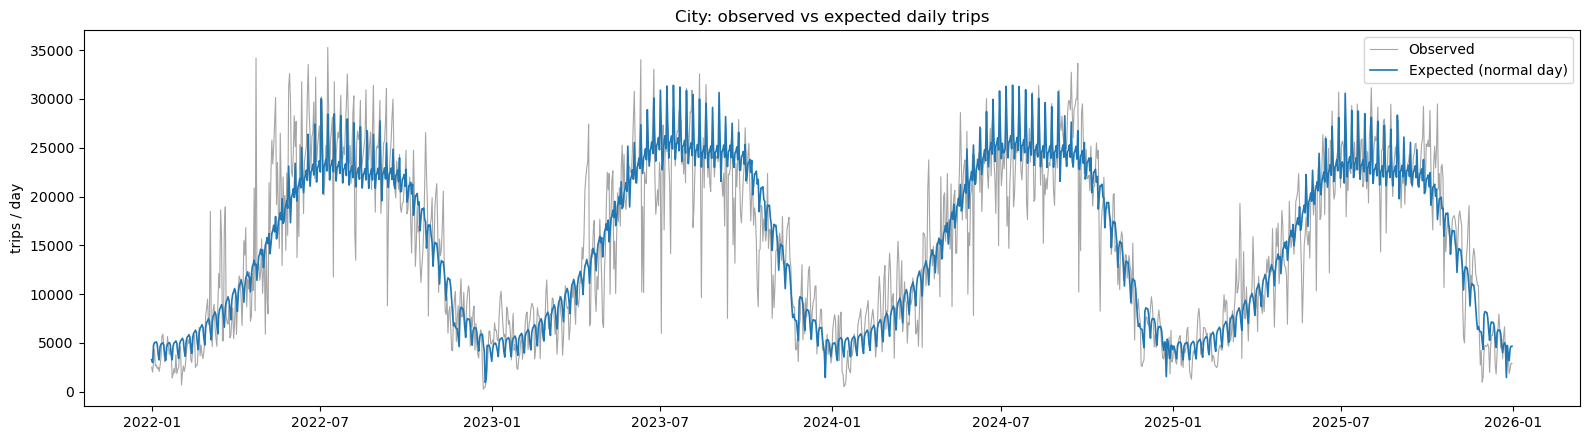

In [7]:
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(city.date, city.n_trips, color="gray", lw=.8, alpha=.7, label="Observed")
ax.plot(city.date, city.mu, color="tab:blue", lw=1.2, label="Expected (normal day)")
ax.set_title("City: observed vs expected daily trips"); ax.set_ylabel("trips / day"); ax.legend()
plt.tight_layout(); plt.show()

### 1.3 Cell data 
The cell file has one row per day x cell. Column names are detected below; change them if needed.

In [8]:
HAVE_CELLS = os.path.exists(CELLS_PATH)
if not HAVE_CELLS:
    print(f"{CELLS_PATH} not found: cell-level parts are skipped (city-level results are still complete).")
else:
    raw = pd.read_parquet(CELLS_PATH)
    print("columns:", list(raw.columns))
    pick = lambda options: next((c for c in options if c in raw.columns), None)
    DATE_COL  = pick(["date", "day"])
    CELL_COL  = pick(["cell", "cell_id", "zone", "zone_id", "area", "area_id"])
    COUNT_COL = pick(["n_trips", "trips", "count", "n"])
    assert DATE_COL and CELL_COL and COUNT_COL, "set DATE_COL / CELL_COL / COUNT_COL by hand (see printed columns)"
    cells = raw[[DATE_COL, CELL_COL, COUNT_COL]].rename(columns={DATE_COL: "date", CELL_COL: "cell", COUNT_COL: "n_trips"})
    cells["date"] = pd.to_datetime(cells.date)
    cells = cells[(cells.date >= START) & (cells.date <= END)]
    # complete grid: a missing (day, cell) row is read as 0 trips -> check how many we had to add
    grid = pd.MultiIndex.from_product([pd.date_range(START, END), sorted(cells.cell.unique())], names=["date", "cell"])
    cells = cells.set_index(["date", "cell"]).reindex(grid)
    n_added = int(cells.n_trips.isna().sum())
    cells = cells.fillna({"n_trips": 0}).reset_index()
    cells["n_trips"] = cells.n_trips.astype(int)
    cells["cell"] = cells.cell.astype(str)
    print(f"{cells.cell.nunique()} cells x {cells.date.nunique()} days = {len(cells)} cell-days ({n_added} rows added as 0)")
    cells = add_features(cells.merge(calendar_df, on="date", how="left"))

columns: ['date', 'cell_id', 'n_trips', 'n_casual', 'n_electric', 'cell_name']
37 cells x 1461 days = 54057 cell-days (0 rows added as 0)


In [9]:
if HAVE_CELLS:
    # Cell model: same calendar terms + a level per cell (+ optional cell x weekend, cell x season)
    cell_terms = ["C(cell)"] + CAL_TERMS
    if USE_CELL_INTERACTIONS:
        cell_terms += ["C(cell):is_weekend", "C(cell):sin1", "C(cell):cos1"]
    formula_cells = "n_trips ~ " + " + ".join(cell_terms)
    cells = cells.reset_index(drop=True)
    res_cells, cells["mu"], keep_cells = fit_nb_robust(cells, formula_cells, rounds=1)
    alpha_cells = res_cells.params["alpha"]
    print(f"\nalpha (cells, shared by all cells) = {alpha_cells:.4f}   AIC = {res_cells.aic:.0f}")

round 0: alpha=0.1418, days left out of the fit=445
round 1: alpha=0.1253, days left out of the fit=576

alpha (cells, shared by all cells) = 0.1253   AIC = 548220


### 1.4 Check the fit
Mean residual by weekday and by month: all bars should be close to 0. (Weather is missing, so winter months are expected to be the least good.)

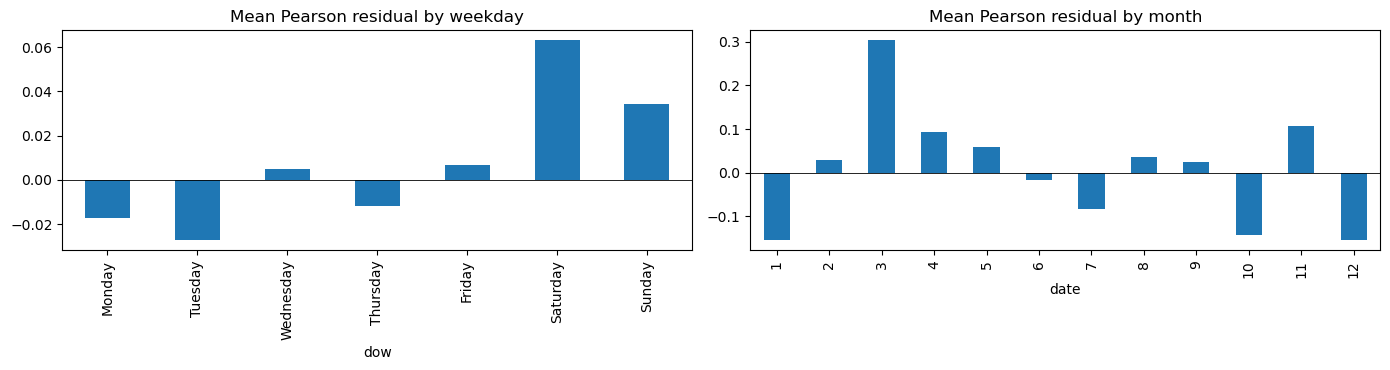

In [10]:
city["pearson"] = (city.n_trips - city.mu) / np.sqrt(city.mu + alpha_city * city.mu**2)
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
city.groupby("dow").pearson.mean().reindex(order).plot.bar(ax=ax[0], title="Mean Pearson residual by weekday")
city.groupby(city.date.dt.month).pearson.mean().plot.bar(ax=ax[1], title="Mean Pearson residual by month")
for a in ax: a.axhline(0, c="k", lw=.6)
plt.tight_layout(); plt.show()

## 2. Why a negative binomial: variance vs mean

Group days that should behave alike (same year, month and type of day). Within each group, compute the mean and the variance of the daily count. If counts were Poisson, points would follow variance = mean. With a negative binomial, they follow variance $= \mu + \alpha\mu^2$.

City: variance/mean ratio is 709 (median over groups); alpha from this plot = 0.030, alpha from the model = 0.074


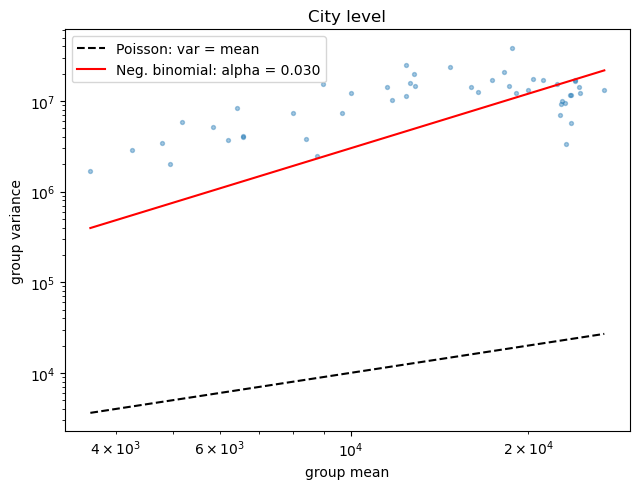

In [11]:
def var_mean_table(df, group_cols):
    g = df.groupby(group_cols).n_trips.agg(["mean", "var", "count"])
    return g[(g["count"] >= 8) & (g["mean"] > 0)].rename(columns={"mean": "m", "var": "v"})

def alpha_from_groups(g):
    """Moment estimate: (v - m) ~ alpha * m^2, least squares through the origin."""
    return float(np.sum((g.v - g.m) * g.m**2) / np.sum(g.m**4))

def plot_var_mean(g, alpha, title, ax):
    ax.scatter(g.m, g.v, s=8, alpha=.4)
    xs = np.logspace(np.log10(g.m.min()), np.log10(g.m.max()), 100)
    ax.plot(xs, xs, "k--", label="Poisson: var = mean")
    ax.plot(xs, xs + alpha * xs**2, "r", label=f"Neg. binomial: alpha = {alpha:.3f}")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("group mean"); ax.set_ylabel("group variance")
    ax.set_title(title); ax.legend()

city["daytype"] = np.where(city.is_major_holiday, "holiday", np.where(city.is_weekend == 1, city.dow, "weekday"))
g_city = var_mean_table(city, ["year", city.date.dt.month.rename("month"), "daytype"])
a_city_vm = alpha_from_groups(g_city)
print(f"City: variance/mean ratio is {np.median(g_city.v / g_city.m):.0f} (median over groups); alpha from this plot = {a_city_vm:.3f}, alpha from the model = {alpha_city:.3f}")
fig, ax = plt.subplots(figsize=(6.5, 5)); plot_var_mean(g_city, a_city_vm, "City level", ax); plt.tight_layout(); plt.show()

Cells: alpha from this plot = 0.031, alpha from the model = 0.125


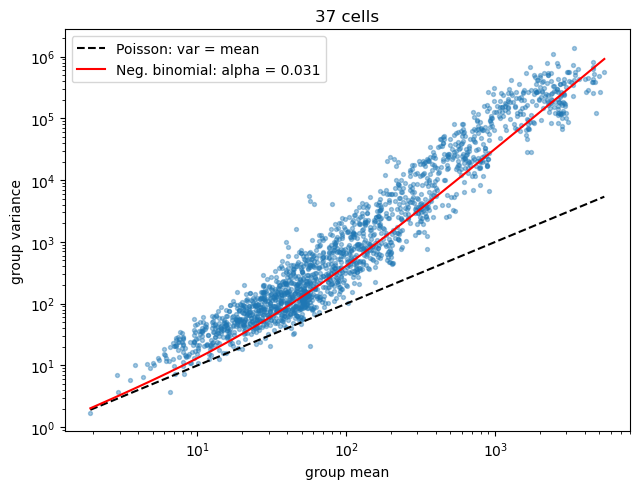

In [12]:
if HAVE_CELLS:
    cells["daytype"] = np.where(cells.is_major_holiday, "holiday", np.where(cells.is_weekend == 1, cells.dow, "weekday"))
    g_cells = var_mean_table(cells, ["cell", "year", cells.date.dt.month.rename("month"), "daytype"])
    a_cells_vm = alpha_from_groups(g_cells)
    print(f"Cells: alpha from this plot = {a_cells_vm:.3f}, alpha from the model = {alpha_cells:.3f}")
    fig, ax = plt.subplots(figsize=(6.5, 5)); plot_var_mean(g_cells, a_cells_vm, f"{cells.cell.nunique()} cells", ax); plt.tight_layout(); plt.show()

**How to read it.** Points far above the dashed Poisson line mean the counts are overdispersed, and a Poisson model is not appropriate. The red curve should follow the cloud. If the cell plot sits above the city plot at low means, quiet cells are noisier relative to their size, and one shared $\alpha$ may be too small for them (possible extension: one $\alpha$ per group of cells).

## 3. Anomaly score

For a day (or cell-day) with observed count $y$ and expected count $\mu$, two views of "how surprising":

- **Pearson residual** $r = \dfrac{y-\mu}{\sqrt{\mu+\alpha\mu^2}}$. About how many standard deviations away; negative = unusually low, positive = unusually high. Easy to read and to plot.
- **Negative binomial p-value.** The probability of a count at least as extreme as the one observed if the model were true: $p_{\text{low}} = P(X \le y)$, $p_{\text{high}} = P(X \ge y)$, and the two-sided $p = \min\!\big(1,\ 2\min(p_{\text{low}}, p_{\text{high}})\big)$. The direction is the side with the smaller tail. This is the number used for multiple testing in section 4.

In [13]:
def anomaly_scores(y, mu, alpha):
    y = np.asarray(y); mu = np.asarray(mu)
    pearson = (y - mu) / np.sqrt(mu + alpha * mu**2)
    n = 1.0 / alpha; p = n / (n + mu)
    p_low = stats.nbinom.cdf(y, n, p)           # P(X <= y)
    p_high = stats.nbinom.sf(y - 1, n, p)       # P(X >= y)
    p_two = np.minimum(1.0, 2 * np.minimum(p_low, p_high))
    direction = np.where(p_low < p_high, "low", "high")
    return pearson, p_two, direction

city["pearson"], city["p_value"], city["direction"] = anomaly_scores(city.n_trips, city.mu, alpha_city)
city["ratio"] = city.n_trips / city.mu
print("Pearson residuals: mean %.2f, sd %.2f (should be about 0 and 1)" % (city.pearson.mean(), city.pearson.std()))
cols = ["date", "dow", "n_trips", "mu", "ratio", "pearson", "p_value", "direction", "holiday_name"]
print("\nTop 10 most surprising days (city):")
city.assign(a=city.pearson.abs()).sort_values("a", ascending=False).head(10)[cols].round(4)

Pearson residuals: mean 0.01, sd 1.09 (should be about 0 and 1)

Top 10 most surprising days (city):


,date,dow,n_trips,mu,ratio,pearson,p_value,direction,holiday_name
63,2022-03-05,Saturday,18472,6083.1850,3.0366,7.5006,0.0000,high,
112,2022-04-23,Saturday,34185,13060.6975,2.6174,5.9604,0.0000,high,
78,2022-03-20,Sunday,16847,6609.2478,2.5490,5.7054,0.0000,high,
792,2024-03-03,Sunday,14199,5683.4331,2.4983,5.5178,0.0000,high,
1168,2025-03-14,Friday,19303,8269.7533,2.3342,4.9151,0.0002,high,
79,2022-03-21,Monday,18939,8554.5789,2.2139,4.4722,0.0005,high,
834,2024-04-14,Sunday,23756,10938.4356,2.1718,4.3178,0.0008,high,
469,2023-04-15,Saturday,27408,12709.6853,2.1565,4.2617,0.0009,high,
74,2022-03-16,Wednesday,18634,8647.0623,2.1550,4.2550,0.0009,high,
1169,2025-03-15,Saturday,15489,7190.6474,2.1540,4.2510,0.0009,high,


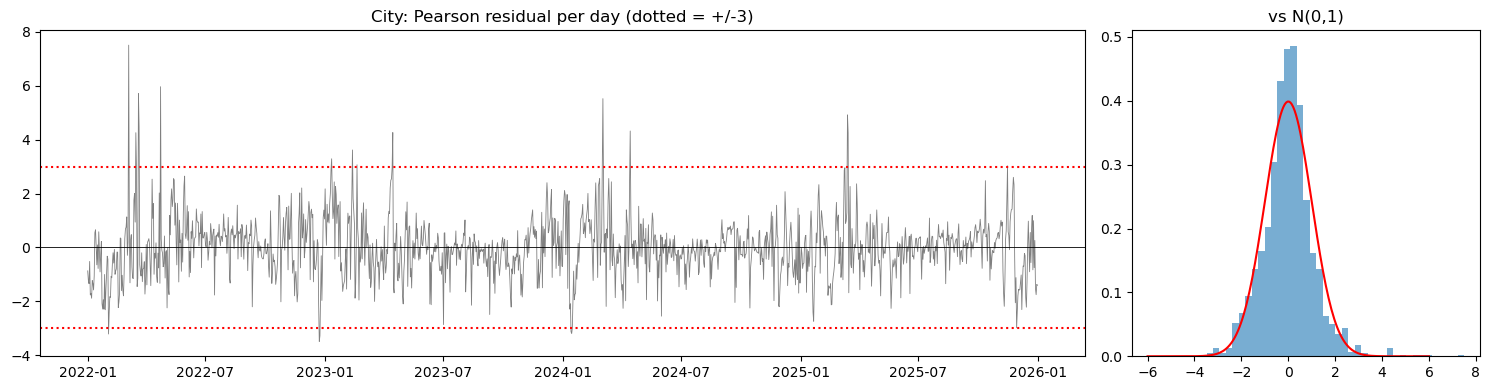

Known test case, 13-17 Jan 2024:


,date,n_trips,mu,ratio,pearson,p_value,direction
742,2024-01-13,1790,4133.8460,0.4330,-2.0871,0.0091,low
743,2024-01-14,540,3551.6835,0.1520,-3.1205,0.0000,low
744,2024-01-15,671,5044.9434,0.1330,-3.1924,0.0000,low
745,2024-01-16,1029,5374.7284,0.1915,-2.9774,0.0000,low
746,2024-01-17,2645,5429.2507,0.4872,-1.8885,0.0233,low


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [3, 1]})
ax[0].plot(city.date, city.pearson, lw=.6, color="gray")
ax[0].axhline(0, c="k", lw=.6); ax[0].axhline(3, c="r", ls=":"); ax[0].axhline(-3, c="r", ls=":")
ax[0].set_title("City: Pearson residual per day (dotted = +/-3)")
ax[1].hist(city.pearson, bins=40, density=True, alpha=.6)
xs = np.linspace(-6, 6, 200); ax[1].plot(xs, stats.norm.pdf(xs), "r"); ax[1].set_title("vs N(0,1)")
plt.tight_layout(); plt.show()

# Known test case in the study period: 13-17 January 2024 (cold snap) should come out low
test_days = city[(city.date >= "2024-01-13") & (city.date <= "2024-01-17")][["date", "n_trips", "mu", "ratio", "pearson", "p_value", "direction"]]
print("Known test case, 13-17 Jan 2024:"); test_days.round(4)

## 4. Multiple testing: Benjamini–Hochberg

Each day (or cell-day) is a statistical test. Flagging every p-value below 0.01 means about 1 % of all *normal* days are flagged by chance, which is a lot when there are 54 000 cell-days. Benjamini–Hochberg (BH) fixes the **false discovery rate**: among the days flagged, we accept at most a share $q$ of false alarms. Procedure: sort the $m$ p-values, find the largest $k$ with $p_{(k)} \le \tfrac{k}{m}\,q$, and flag the $k$ smallest.

In [15]:
def bh(p, q=Q_FDR):
    reject, p_adj, _, _ = multipletests(p, alpha=q, method="fdr_bh")
    return reject, p_adj

def summarize_tests(p, name):
    m = len(p)
    raw = int((p < RAW_ALPHA).sum())
    rej, _ = bh(p)
    print(f"{name}: {m} tests")
    print(f"  raw p < {RAW_ALPHA}: {raw} flagged, of which about {m*RAW_ALPHA:.0f} expected by chance alone if there were no anomalies")
    print(f"  BH at q = {Q_FDR}: {int(rej.sum())} flagged, at most about {Q_FDR*100:.0f} % of them false")
    return rej

city["bh_flag"], city["p_adj"] = bh(city.p_value.values)
_ = summarize_tests(city.p_value.values, "City (days)")
city[city.bh_flag].assign(a=lambda x: x.pearson.abs()).sort_values("a", ascending=False).head(15)[cols + ["p_adj"]].round(4)

City (days): 1461 tests
  raw p < 0.01: 53 flagged, of which about 15 expected by chance alone if there were no anomalies
  BH at q = 0.05: 16 flagged, at most about 5 % of them false


,date,dow,n_trips,mu,ratio,pearson,p_value,direction,holiday_name,p_adj
63,2022-03-05,Saturday,18472,6083.1850,3.0366,7.5006,0.0000,high,,0.0001
112,2022-04-23,Saturday,34185,13060.6975,2.6174,5.9604,0.0000,high,,0.0025
78,2022-03-20,Sunday,16847,6609.2478,2.5490,5.7054,0.0000,high,,0.0042
792,2024-03-03,Sunday,14199,5683.4331,2.4983,5.5178,0.0000,high,,0.0060
1168,2025-03-14,Friday,19303,8269.7533,2.3342,4.9151,0.0002,high,,0.0210
79,2022-03-21,Monday,18939,8554.5789,2.2139,4.4722,0.0005,high,,0.0498
356,2022-12-23,Friday,261,4859.4738,0.0537,-3.4842,0.0000,low,,0.0000
357,2022-12-24,Saturday,464,4138.5905,0.1121,-3.2683,0.0000,low,,0.0000
32,2022-02-02,Wednesday,685,5321.9135,0.1287,-3.2084,0.0000,low,,0.0000
744,2024-01-15,Monday,671,5044.9434,0.1330,-3.1924,0.0000,low,Martin Luther King Jr. Day,0.0000


H0: the day is normal (counts follow NB with mean μ and dispersion α).
Small p-value: the count would be very surprising under H0, so we flag it as an anomaly.
Large p-value: nothing surprising, so we don’t flag it. This does not prove the day is normal. It may be that the test lacked the power to see a small anomaly, which is the “unknown ≠ normal” idea in section 6.


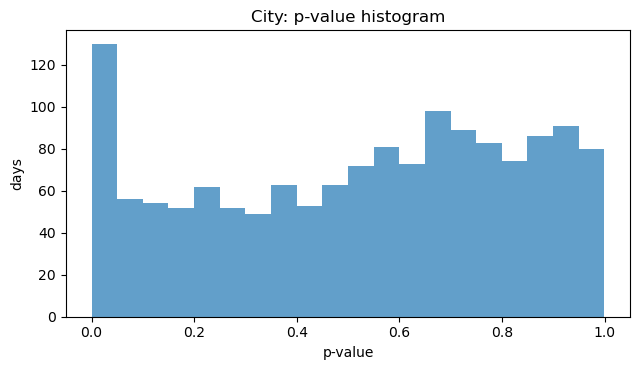

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(city.p_value, bins=20, color="tab:blue", alpha=.7)
ax.set_title("City: p-value histogram"); ax.set_xlabel("p-value"); ax.set_ylabel("days")
plt.tight_layout(); plt.show()

**Reading the histogram.** If the model were perfect and there were no anomalies, the bars would be flat. A spike at 0 is the genuine anomalies; a spike at 0 that is too large, or a U shape, means the model is too tight or the variance is mis-specified.
A spike in the first bar (0–0.05). There are about 130 days where the flat line would give 73. That is about 55 extra days that look genuinely unusual. They’re the candidates for real anomalies (cold snaps, holidays, events, ).
The rest is not perfectly flat. The bars between 0.05 and 0.45 are around 50–60, below 73. The bars between 0.65 and 1.0 are 80–98, above 73. So there are slightly too many days that look very ordinary and too few that look mildly unusual.



Cells (cell-days): 54057 tests
  raw p < 0.01: 1131 flagged, of which about 541 expected by chance alone if there were no anomalies
  BH at q = 0.05: 160 flagged, at most about 5 % of them false

           flagged cell-days (BH)
direction                        
high                           74
low                            86


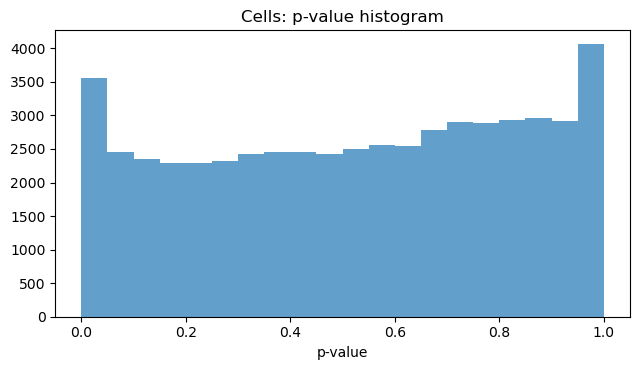

In [17]:
if HAVE_CELLS:
    cells["pearson"], cells["p_value"], cells["direction"] = anomaly_scores(cells.n_trips, cells.mu, alpha_cells)
    cells["ratio"] = cells.n_trips / cells.mu
    cells["bh_flag"], cells["p_adj"] = bh(cells.p_value.values)
    _ = summarize_tests(cells.p_value.values, "Cells (cell-days)")
    print()
    print(cells[cells.bh_flag].groupby("direction").size().to_frame("flagged cell-days (BH)"))
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    ax.hist(cells.p_value, bins=20, alpha=.7); ax.set_title("Cells: p-value histogram"); ax.set_xlabel("p-value")
    plt.tight_layout(); plt.show()

In [18]:
if HAVE_CELLS:
    # How are flagged cell-days spread over days and cells? City-wide days (many cells at once) look like weather/events.
    per_day = cells[cells.bh_flag].groupby("date").size().rename("n_cells_flagged")
    print("Days with the most cells flagged:")
    display(per_day.sort_values(ascending=False).head(10).to_frame())
    print("Cells with the most flagged days:")
    display(cells[cells.bh_flag].groupby("cell").size().sort_values(ascending=False).head(10).to_frame("n_days_flagged"))

Days with the most cells flagged:


,n_cells_flagged
date,
2022-12-23,21
2022-12-24,15
2022-02-02,14
2024-01-15,11
2022-03-05,9
2024-01-14,9
2022-03-21,7
2022-03-20,6
2024-01-16,5


Cells with the most flagged days:


,n_days_flagged
cell,
19,17
12,12
7,11
24,11
3,7
31,6
20,6
37,6
5,6


### 4.1 What can this actually detect? (power)
With overdispersion, even a large cell has relative noise of about $\sqrt{\alpha}$ (for $\alpha = 0.084$ that is about 29 %), and with tens of thousands of tests BH asks for a very small p-value. So only large changes can be flagged at the cell-day level, and a cell-day with no flag is **unknown**, not necessarily normal. The table gives, for several expected counts $\mu$, the smallest drop and rise that would be flagged (using the BH threshold actually reached by your data).

In [19]:
def bh_threshold(p, q=Q_FDR):
    p_sorted = np.sort(np.asarray(p)); m = len(p_sorted)
    ok = np.nonzero(p_sorted <= np.arange(1, m + 1) / m * q)[0]
    return p_sorted[ok.max()] if len(ok) else q / m   # nothing flagged: use the strictest step q/m

def min_detectable(alpha, p_thr, mus=(10, 20, 50, 100, 300, 1000, 5000)):
    rows = []
    tail = p_thr / 2                      # two-sided p = 2 * smaller tail
    n = 1.0 / alpha
    for mu in mus:
        pr = n / (n + mu)
        y_lo = stats.nbinom.ppf(tail, n, pr)
        if stats.nbinom.cdf(y_lo, n, pr) > tail: y_lo -= 1        # largest y with P(X <= y) <= tail
        y_hi = stats.nbinom.isf(tail, n, pr) + 1                  # smallest y with P(X >= y) <= tail
        rows.append({"expected trips (mu)": mu,
                     "smallest flagged drop": f"{100*(y_lo/mu-1):.0f} %" if y_lo >= 0 else "none (even 0 trips is not enough)",
                     "smallest flagged rise": f"+{100*(y_hi/mu-1):.0f} %"})
    return pd.DataFrame(rows).set_index("expected trips (mu)")

if HAVE_CELLS:
    p_ref, a_ref, label = cells.p_value.values, alpha_cells, f"cell-days (m = {len(cells)}, alpha = {alpha_cells:.3f})"
else:
    p_ref, a_ref, label = city.p_value.values, alpha_city, f"days (m = {len(city)}, alpha = {alpha_city:.3f})"
thr = bh_threshold(p_ref)
print(f"BH threshold reached on {label}: p <= {thr:.2e}")
min_detectable(a_ref, thr)

BH threshold reached on cell-days (m = 54057, alpha = 0.125): p <= 1.41e-04


,smallest flagged drop,smallest flagged rise
expected trips (mu),,
10,none (even 0 trips is not enough),+270 %
20,-100 %,+235 %
50,-92 %,+210 %
100,-88 %,+202 %
300,-85 %,+196 %
1000,-84 %,+194 %
5000,-84 %,+194 %


## 5. City-level prototype: do the known test cases come out?

Before trusting the cell model, check the **city model** (one series, quick) on events we already know happened:

- COVID lockdown, April 2020 (very low)
- Cold, February 2021 (low)
- Cold snap, 13–17 January 2024 (low)

April 2020 and February 2021 are outside the 2022–2025 study period, so this section fits a **separate city model on a longer window** (`PROTO_START` to `END`), with the same formula. The school-break flags are only defined from December 2021, so earlier winter and spring breaks are treated as ordinary days here (a small source of noise, fine for a prototype). The question for each case: are the days flagged by Benjamini–Hochberg, in the expected direction, and is the observed count far below the expected one?

In [28]:
PROTO_START = START              # same window as the main model: 2022-2025
KNOWN_CASES = {                  # name: (first day, last day, expected direction)
    "Cold snap, 13-17 Jan 2024":       ("2024-01-13", "2024-01-17", "low"),
    "Winter storm Elliott, 22-23 Dec 2022": ("2022-12-22", "2022-12-23", "low"),
    "Wildfire smoke, 27-29 Jun 2023":  ("2023-06-27", "2023-06-29", "low"),
}

cal_p = add_holiday_context(add_school_breaks(build_calendar(PROTO_START, END)))
proto = pd.read_csv(CITY_PATH, parse_dates=["date"])
proto = proto[(proto.date >= PROTO_START) & (proto.date <= END)]
proto = add_features(proto.merge(cal_p, on="date", how="left")).sort_values("date").reset_index(drop=True)
print(f"Prototype window: {proto.date.min().date()} -> {proto.date.max().date()}, {len(proto)} days")

res_p, proto["mu"], keep_p = fit_nb_robust(proto, formula_city)
alpha_p = res_p.params["alpha"]
proto["pearson"], proto["p_value"], proto["direction"] = anomaly_scores(proto.n_trips, proto.mu, alpha_p)
proto["ratio"] = proto.n_trips / proto.mu
proto["bh_flag"], proto["p_adj"] = bh(proto.p_value.values)
print(f"alpha (prototype) = {alpha_p:.4f}; BH flags {int(proto.bh_flag.sum())} of {len(proto)} days")

Prototype window: 2022-01-01 -> 2025-12-31, 1461 days
round 0: alpha=0.0940, days left out of the fit=15
round 1: alpha=0.0779, days left out of the fit=24
round 2: alpha=0.0736, days left out of the fit=26
alpha (prototype) = 0.0736; BH flags 16 of 1461 days


In [29]:
rows = []
in_any = pd.Series(False, index=proto.index)
for name, (a, b, expected) in KNOWN_CASES.items():
    m = (proto.date >= a) & (proto.date <= b)
    in_any |= m
    s = proto[m]
    if len(s) == 0:
        rows.append({"test case": name, "days with data": 0}); continue
    hit = s.bh_flag & (s.direction == expected)
    rows.append({"test case": name, "days with data": len(s),
                 "flagged (BH, expected direction)": int(hit.sum()),
                 "share flagged": f"{100*hit.mean():.0f} %",
                 "median observed/expected": round(s.ratio.median(), 2),
                 "most extreme Pearson": round(s.pearson.abs().max() * np.sign(s.loc[s.pearson.abs().idxmax(), "pearson"]), 1)})
table = pd.DataFrame(rows).set_index("test case")
base = proto[~in_any]
print(f"Outside the test cases: {100*base.bh_flag.mean():.1f} % of days flagged (BH), {int(base.bh_flag.sum())} days")
table

Outside the test cases: 0.8 % of days flagged (BH), 12 days


,days with data,"flagged (BH, expected direction)",share flagged,median observed/expected,most extreme Pearson
test case,,,,,
"Cold snap, 13-17 Jan 2024",5,3,60 %,0.19,-3.2
"Winter storm Elliott, 22-23 Dec 2022",2,1,50 %,0.24,-3.5
"Wildfire smoke, 27-29 Jun 2023",3,0,0 %,0.77,-1.0


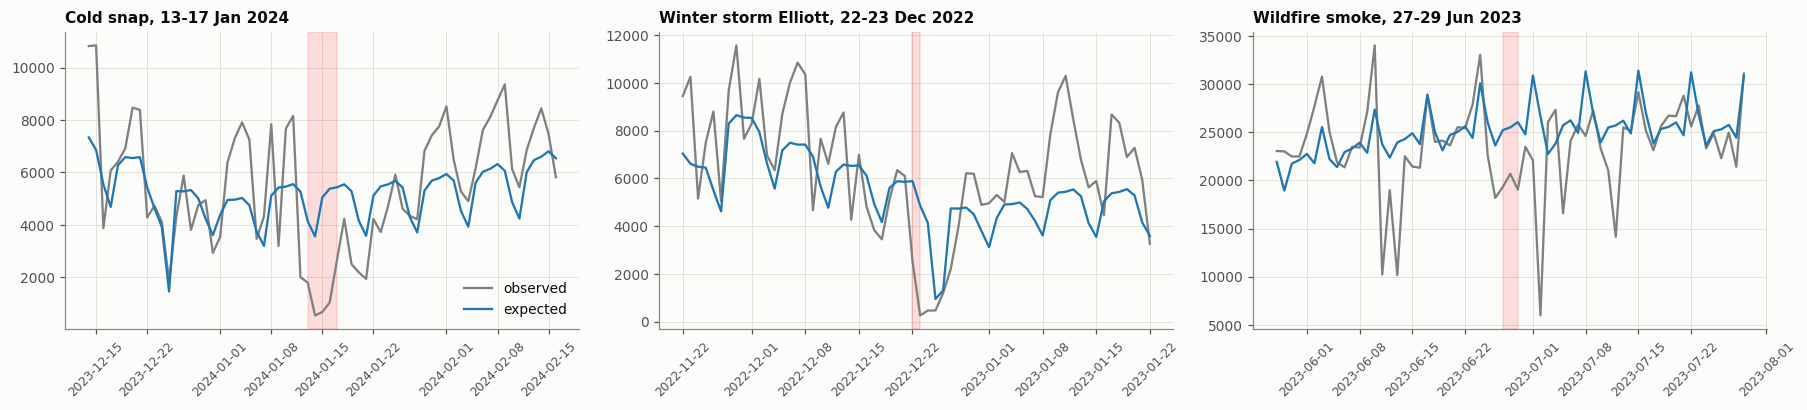

In [30]:
avail = [(n, v) for n, v in KNOWN_CASES.items() if ((proto.date >= v[0]) & (proto.date <= v[1])).any()]
fig, axes = plt.subplots(1, max(len(avail), 1), figsize=(5.5 * max(len(avail), 1), 3.8), squeeze=False)
for ax, (name, (a, b, _)) in zip(axes[0], avail):
    w = proto[(proto.date >= pd.Timestamp(a) - pd.Timedelta(days=30)) & (proto.date <= pd.Timestamp(b) + pd.Timedelta(days=30))]
    ax.plot(w.date, w.n_trips, color="gray", label="observed"); ax.plot(w.date, w.mu, color="tab:blue", label="expected")
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="red", alpha=.12)
    ax.set_title(name, fontsize=10); ax.tick_params(axis="x", labelrotation=45, labelsize=8)
axes[0][0].legend(); plt.tight_layout(); plt.show()

**How to read it.** A good city model flags most days of each test case in the expected direction, with an observed/expected ratio well below 1, and flags only a small share of other days. If a case is not flagged, either the model is too noisy (alpha too large) or the effect is smaller than the noise floor (see section 6).

## 6. Power: how large an anomaly could we have seen?

We test every cell-day, but a test can only flag a change that is bigger than the noise. Two ingredients decide this:

- the expected count $\mu$ (small cells are noisy in relative terms), and
- the overdispersion $\alpha$: even for large $\mu$, the relative noise does not fall below about $\sqrt{\alpha}$.

The rule of thumb in the team document (random noise about $\sqrt n$, so a relative change $d$ needs $n > 4/d^2$) only counts Poisson noise. With overdispersion and a very strict BH threshold it is too optimistic. For each cell-day we compute the **smallest drop and the smallest rise that would have been flagged**, using the BH threshold actually reached.

A cell-day with no anomaly found and low power is labelled **unknown**, not **normal**.

In [23]:
D_TARGET = 0.5   # question asked of every cell-day: would a 50 % drop, or a +50 % rise, have been flagged?

def detectability(mu, alpha, p_thr):
    """Smallest relative drop (fraction of mu that must disappear) and smallest relative rise that give p <= p_thr (two-sided)."""
    mu = np.asarray(mu, float); n = 1.0 / alpha; pr = n / (n + mu); tail = p_thr / 2
    y_lo = stats.nbinom.ppf(tail, n, pr)
    y_lo = np.where(stats.nbinom.cdf(y_lo, n, pr) > tail, y_lo - 1, y_lo)     # largest y with P(X <= y) <= tail
    y_hi = stats.nbinom.isf(tail, n, pr) + 1                                  # smallest y with P(X >= y) <= tail
    min_drop = np.where(y_lo >= 0, 1 - y_lo / mu, np.nan)                     # nan = even 0 trips would not be flagged
    return min_drop, y_hi / mu - 1

if HAVE_CELLS:
    pw, a_pw, pw_label = cells, alpha_cells, "cell-days"
else:
    pw, a_pw, pw_label = city, alpha_city, "days (city)"
p_thr = bh_threshold(pw.p_value.values)
pw["min_drop"], pw["min_rise"] = detectability(pw.mu, a_pw, p_thr)
drop_ok = (pw.min_drop <= D_TARGET).fillna(False); rise_ok = pw.min_rise <= D_TARGET
pw["status"] = np.where(pw.bh_flag, "flagged",
                np.where(drop_ok & rise_ok, "normal (well powered)",
                np.where(drop_ok | rise_ok, "unknown for one direction", "unknown (low power)")))
print(f"{pw_label}: BH threshold p <= {p_thr:.2e}, alpha = {a_pw:.3f}")
(pw.status.value_counts().to_frame("count").assign(share=lambda x: (100 * x["count"] / x["count"].sum()).round(1).astype(str) + " %"))

cell-days: BH threshold p <= 1.41e-04, alpha = 0.125


,count,share
status,,
unknown (low power),53897,99.7 %
flagged,160,0.3 %


In [24]:
# Rule of thumb (Poisson noise only) vs negative binomial with the BH threshold reached
def mu_needed(d, direction, alpha, p_thr):
    grid = np.unique(np.round(np.logspace(0, 6, 800))).astype(float)
    md, mr = detectability(grid, alpha, p_thr)
    ok = (pd.Series(md).fillna(np.inf).values <= d) if direction == "drop" else (mr <= d)
    return f"{int(grid[ok][0])} trips" if ok.any() else "never (noise floor)"

rows = []
for direction, d in [("drop", .8), ("drop", .5), ("drop", .2), ("rise", .2), ("rise", .5), ("rise", 1.0)]:
    rows.append({"change": f"{'-' if direction == 'drop' else '+'}{d:.0%}",
                 "rule of thumb  n > 4/d^2": f"{int(np.ceil(4 / d**2))} trips",
                 f"neg. binomial, alpha = {a_pw:.3f}": mu_needed(d, direction, a_pw, p_thr)})
pd.DataFrame(rows).set_index("change")

,rule of thumb n > 4/d^2,"neg. binomial, alpha = 0.125"
change,,
-80%,7 trips,never (noise floor)
-50%,16 trips,never (noise floor)
-20%,100 trips,never (noise floor)
+20%,100 trips,never (noise floor)
+50%,16 trips,never (noise floor)
+100%,4 trips,never (noise floor)


In [25]:
if HAVE_CELLS:
    per_cell = cells.groupby("cell").agg(mean_expected=("mu", "mean"),
                                         pct_days_drop_detectable=("min_drop", lambda s: 100 * (s <= D_TARGET).mean()),
                                         pct_days_rise_detectable=("min_rise", lambda s: 100 * (s <= D_TARGET).mean()),
                                         pct_flagged=("bh_flag", lambda s: 100 * s.mean())).round(1)
    print(f"Per cell: share of days on which a {D_TARGET:.0%} drop / +{D_TARGET:.0%} rise would have been flagged")
    display(per_cell.sort_values("mean_expected"))

Per cell: share of days on which a 50% drop / +50% rise would have been flagged


,mean_expected,pct_days_drop_detectable,pct_days_rise_detectable,pct_flagged
cell,,,,
32,15.6,0.0,0.0,0.1
10,18.9,0.0,0.0,0.0
21,22.7,0.0,0.0,0.3
9,27.5,0.0,0.0,0.1
27,28.1,0.0,0.0,0.1
19,28.7,0.0,0.0,1.2
34,31.6,0.0,0.0,0.1
33,33.7,0.0,0.0,0.2
11,34.4,0.0,0.0,0.0


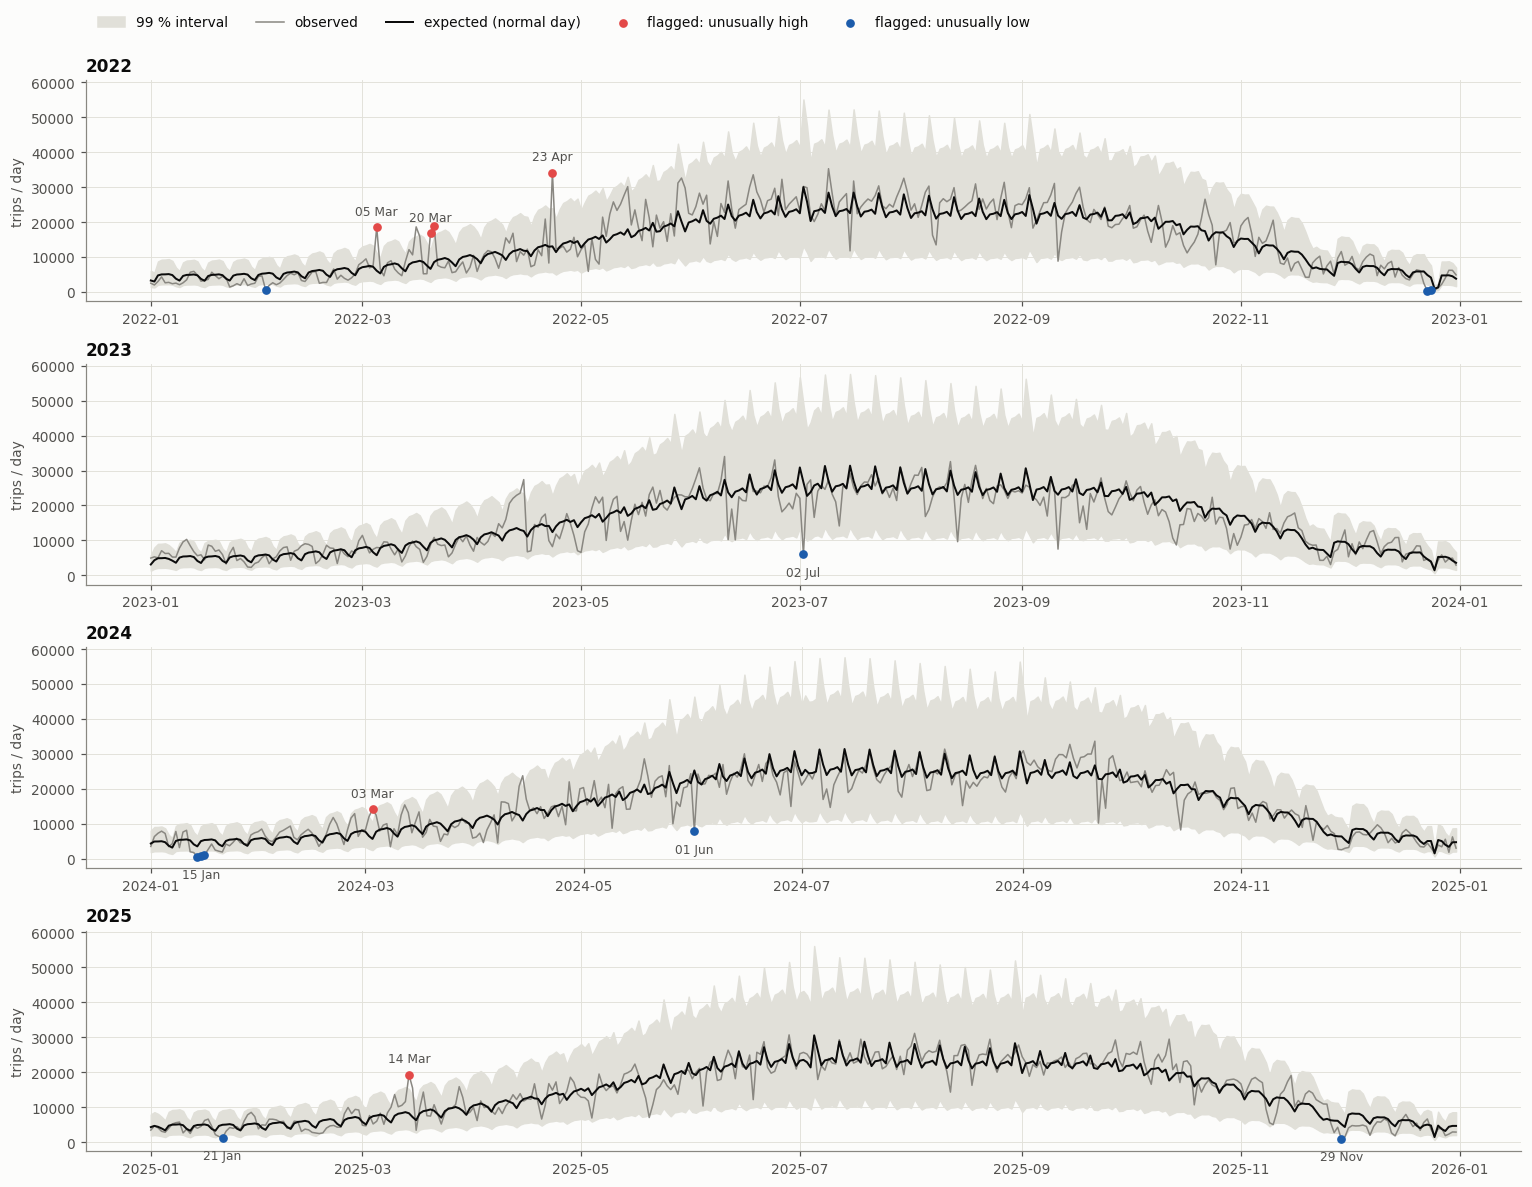

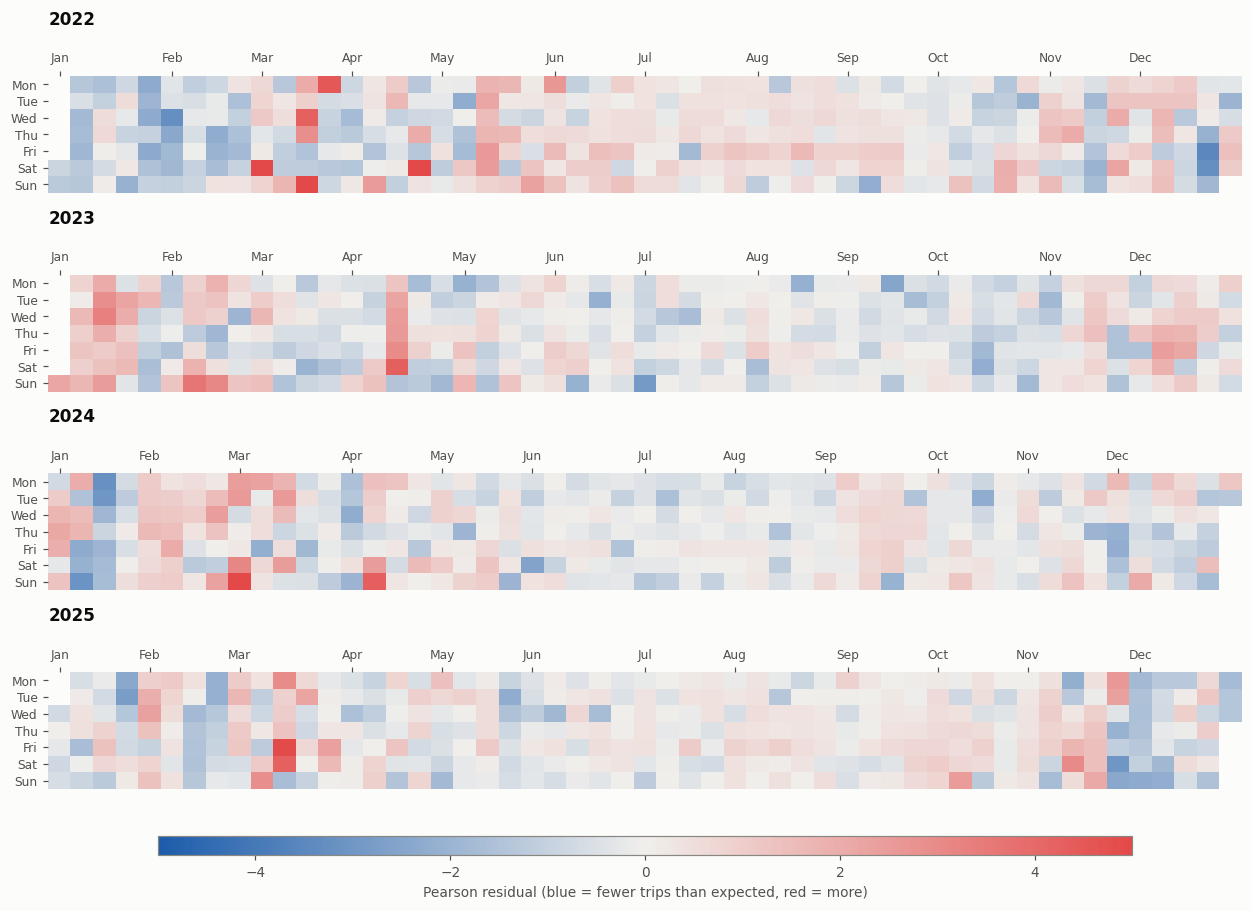

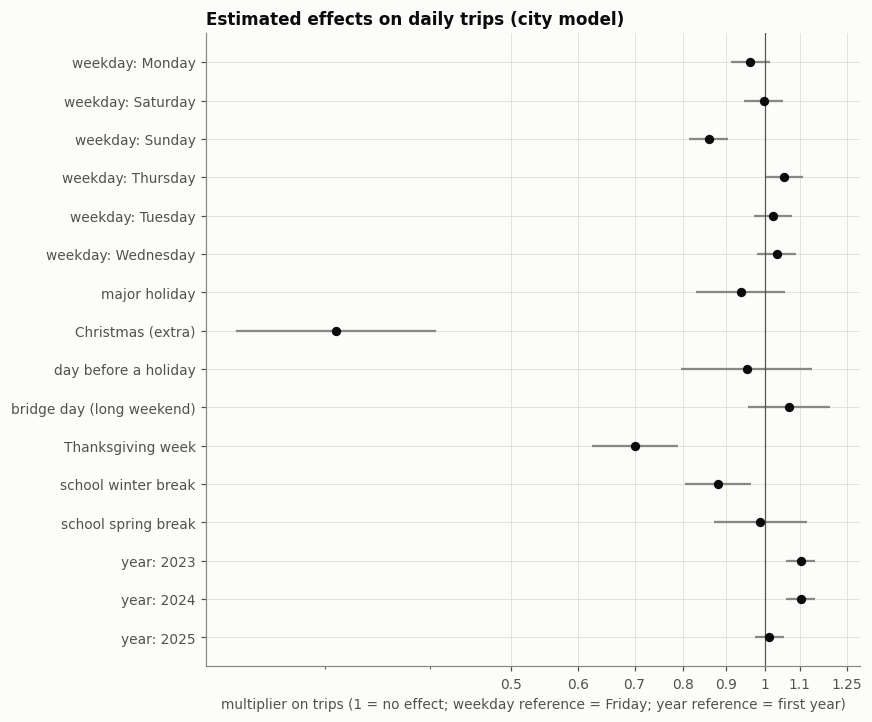

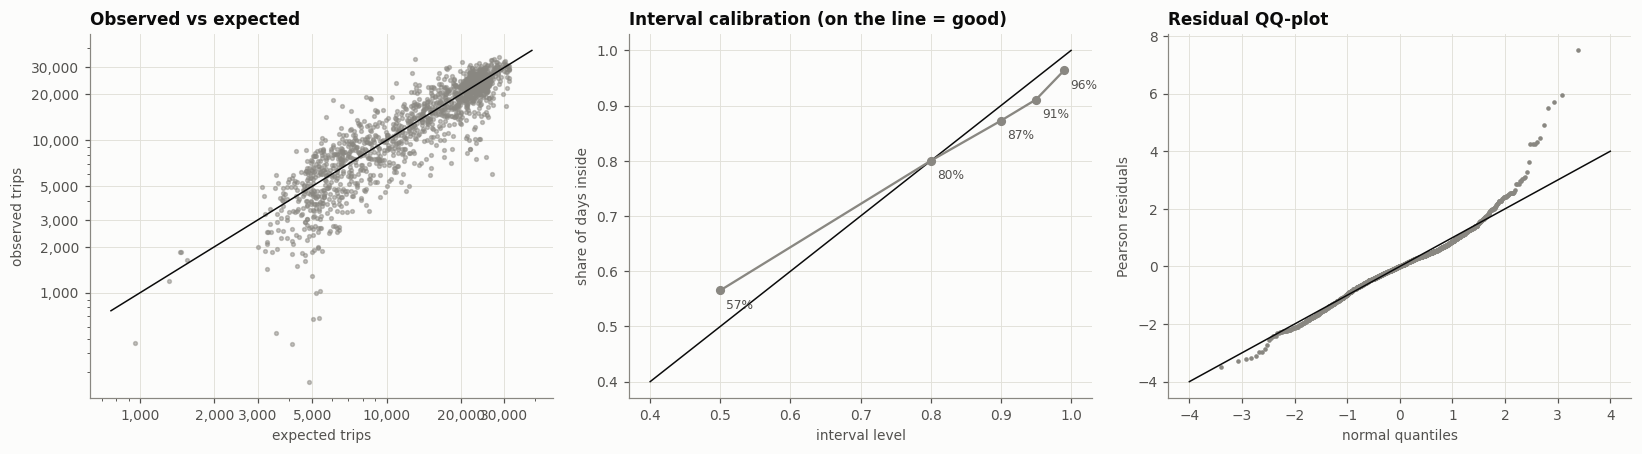

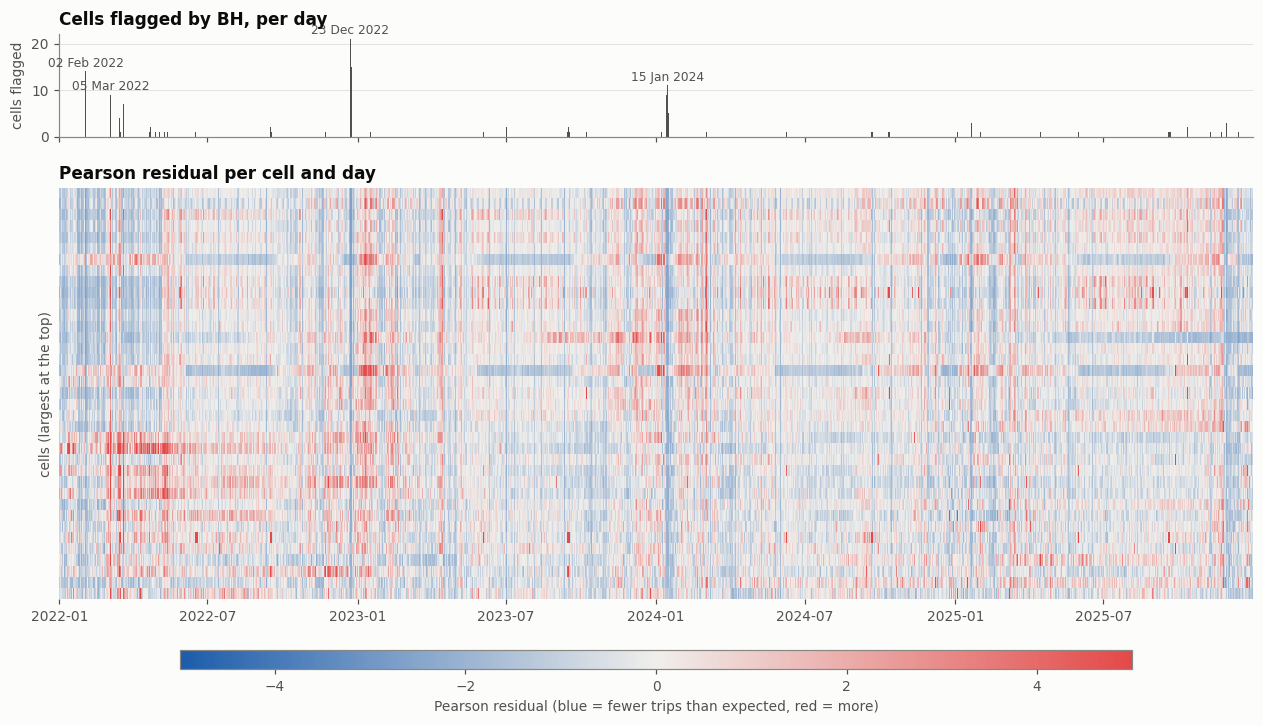

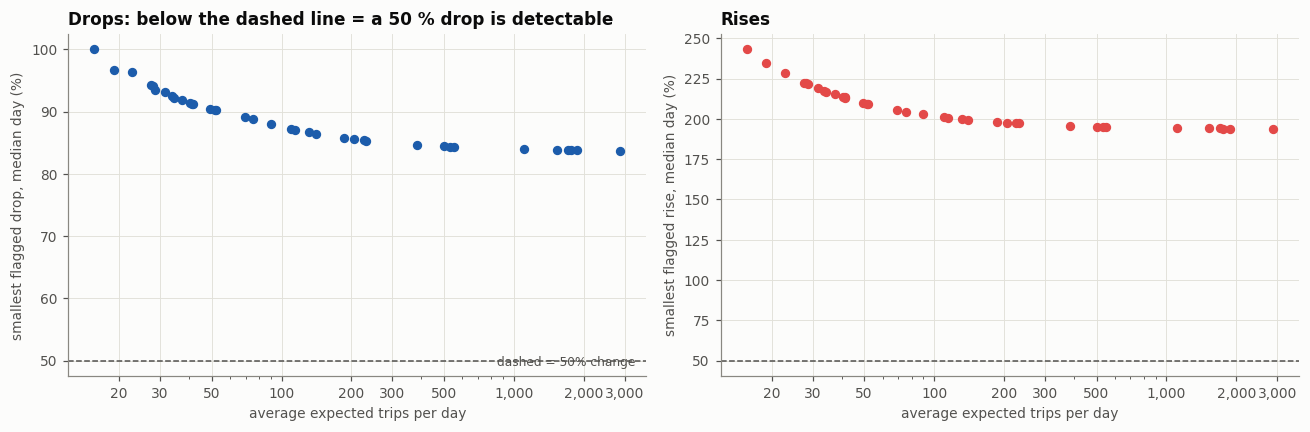

In [27]:
# ======== CELL V0 : style + helpers (run once; section 7 of model.ipynb) ========
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import matplotlib.dates as mdates

INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
LOW_C, HIGH_C, MID_C = "#1c5cab", "#e34948", "#f0efec"        # polarity: blue = unusually low, red = unusually high
DIVERGING = LinearSegmentedColormap.from_list("lowhigh", [LOW_C, MID_C, HIGH_C])
RES_NORM = TwoSlopeNorm(vmin=-5, vcenter=0, vmax=5)            # residuals beyond +/-5 are clipped to the end colour

from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter

def plain_log_ticks(ax, axis, lo, hi):
    """Readable ticks (1, 2, 3, 5 x 10^k) on a log axis, written as plain numbers."""
    ticks = [m * 10 ** k for k in range(-3, 9) for m in (1, 2, 3, 5) if lo * 0.9 <= m * 10 ** k <= hi * 1.1]
    a = ax.xaxis if axis == "x" else ax.yaxis
    a.set_major_locator(FixedLocator(ticks)); a.set_minor_formatter(NullFormatter())
    a.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 1 else f"{v:g}"))

def label_clusters(days, score, min_gap=14, k=3):
    """Pick up to k days to label: the strongest day of each cluster, clusters at least min_gap days apart."""
    chosen = []
    for d_ in score.abs().sort_values(ascending=False).index:
        if all(abs((days[d_] - days[c]).days) >= min_gap for c in chosen):
            chosen.append(d_)
        if len(chosen) == k: break
    return chosen

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
    "axes.axisbelow": True, "legend.frameon": False, "font.size": 9, "figure.dpi": 110,
})


# ======== CELL V1 : the city year by year - observed, expected, 99 % band, flagged days ========
# What to look for: the grey line should wander around the dark line inside the band. Red/blue dots = days flagged by BH.
n_, p_ = 1 / alpha_city, (1 / alpha_city) / (1 / alpha_city + city.mu)
city["lo99"], city["hi99"] = stats.nbinom.ppf(0.005, n_, p_), stats.nbinom.ppf(0.995, n_, p_)
years = sorted(city.date.dt.year.unique())
fig, axes = plt.subplots(len(years), 1, figsize=(14, 2.7 * len(years)), sharey=True)
axes = np.atleast_1d(axes)
for ax, y in zip(axes, years):
    s = city[city.date.dt.year == y]
    ax.fill_between(s.date, s.lo99, s.hi99, color=GRID, label="99 % interval")
    ax.plot(s.date, s.n_trips, color=MUTED, lw=1, label="observed")
    ax.plot(s.date, s.mu, color=INK, lw=1.3, label="expected (normal day)")
    f = s[s.bh_flag]
    ax.scatter(f.date[f.direction == "high"], f.n_trips[f.direction == "high"], color=HIGH_C, s=22, zorder=5, label="flagged: unusually high")
    ax.scatter(f.date[f.direction == "low"], f.n_trips[f.direction == "low"], color=LOW_C, s=22, zorder=5, label="flagged: unusually low")
    if len(f):                                                                   # label the strongest day of up to 3 separate clusters
        for i_ in label_clusters(f.date, f.pearson, k=3):
            r = f.loc[i_]
            ax.annotate(f"{r.date:%d %b}", (r.date, r.n_trips), xytext=(0, -14 if r.direction == "low" else 8),
                        textcoords="offset points", ha="center", fontsize=8, color=INK2)
    ax.set_title(str(y)); ax.set_ylabel("trips / day")
axes[0].legend(ncol=5, loc="upper left", bbox_to_anchor=(0, 1.35))
plt.tight_layout(); plt.show()


# ======== CELL V2 : calendar heatmap of residuals (city) ========
# Rows = weekday, columns = weeks. Blue = fewer trips than expected, red = more, grey = as expected.
# What to look for: grey almost everywhere; stripes along one weekday (= weekday effect badly modelled),
# a vertical block of the same colour (= a multi-day event or a weather spell), or a repeated pattern at the same date every year.
fig, axes = plt.subplots(len(years), 1, figsize=(14, 2.3 * len(years)), gridspec_kw={"hspace": 0.7})
axes = np.atleast_1d(axes)
for ax, y in zip(axes, years):
    s = city[city.date.dt.year == y]
    first = pd.Timestamp(f"{y}-01-01").dayofweek
    col = (s.date.dt.dayofyear - 1 + first) // 7
    grid_ = np.full((7, int(col.max()) + 1), np.nan)
    grid_[s.date.dt.dayofweek.values, col.values] = s.pearson.values
    im = ax.imshow(grid_, aspect="auto", cmap=DIVERGING, norm=RES_NORM, interpolation="nearest")
    ax.set_yticks(range(7)); ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], fontsize=8)
    starts = [(pd.Timestamp(f"{y}-{m:02d}-01").dayofyear - 1 + first) // 7 for m in range(1, 13)]
    ax.set_xticks(starts); ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], fontsize=8)
    ax.xaxis.tick_top(); ax.set_title(str(y), pad=18); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
cb = fig.colorbar(im, ax=axes, orientation="horizontal", fraction=.025, pad=.06, aspect=50)
cb.set_label("Pearson residual (blue = fewer trips than expected, red = more)")
plt.show()


# ======== CELL V3 : what did the model learn? (multipliers with 95 % intervals) ========
# What to look for: do the signs make sense? weekend above 1, Christmas far below 1, year levels moving as you expect.
# Wide whiskers = effect estimated from few days (holidays) - read those with care.
ci = np.exp(res_city.conf_int()); est = np.exp(res_city.params)
keep_rows = [i for i in est.index if i.startswith(("C(dow)", "C(year)", "is_"))]
lab = {"is_major_holiday": "major holiday", "is_christmas": "Christmas (extra)", "is_holiday_eve": "day before a holiday",
       "is_long_weekend": "bridge day (long weekend)", "is_thanksgiving_week": "Thanksgiving week",
       "is_winter_break": "school winter break", "is_spring_break": "school spring break"}
names = [lab.get(i.split("[")[0], i.replace("C(dow)[T.", "weekday: ").replace("C(year)[T.", "year: ").rstrip("]")) for i in keep_rows]
tbl = pd.DataFrame({"name": names, "est": est[keep_rows].values, "lo": ci.loc[keep_rows, 0].values, "hi": ci.loc[keep_rows, 1].values})
fig, ax = plt.subplots(figsize=(8, 0.34 * len(tbl) + 1.2))
yy = np.arange(len(tbl))[::-1]
ax.hlines(yy, tbl.lo, tbl.hi, color=MUTED, lw=1.5); ax.scatter(tbl.est, yy, color=INK, s=26, zorder=5)
ax.axvline(1, color=INK2, lw=.8); ax.set_xscale("log")
cand = [.5, .6, .7, .8, .9, 1, 1.1, 1.25, 1.5, 2, 3, 5]
ax.xaxis.set_major_locator(FixedLocator([t for t in cand if tbl.lo.min() * .93 <= t <= tbl.hi.max() * 1.07]))
ax.xaxis.set_minor_formatter(NullFormatter()); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_yticks(yy); ax.set_yticklabels(tbl.name); ax.set_xlabel("multiplier on trips (1 = no effect; weekday reference = Friday; year reference = first year)")
ax.set_title("Estimated effects on daily trips (city model)")
plt.tight_layout(); plt.show()


# ======== CELL V4 : is the model calibrated? three checks (city) ========
# Left: observed vs expected should hug the diagonal. Middle: the share of days inside each interval should match its nominal level.
# Right: residuals should follow the straight line (beyond +/-3 = the anomalies).
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].scatter(city.mu, city.n_trips, s=6, color=MUTED, alpha=.5)
lims = [city.mu.min() * .8, max(city.mu.max(), city.n_trips.max()) * 1.1]
ax[0].plot(lims, lims, color=INK, lw=1); ax[0].set_xscale("log"); ax[0].set_yscale("log")
plain_log_ticks(ax[0], "x", lims[0], lims[1]); plain_log_ticks(ax[0], "y", lims[0], lims[1])
ax[0].set_xlabel("expected trips"); ax[0].set_ylabel("observed trips"); ax[0].set_title("Observed vs expected")

levels = np.array([.5, .8, .9, .95, .99])
inside = [np.mean((city.n_trips >= stats.nbinom.ppf((1 - l) / 2, n_, p_)) & (city.n_trips <= stats.nbinom.ppf(1 - (1 - l) / 2, n_, p_))) for l in levels]
ax[1].plot([0.4, 1], [0.4, 1], color=INK, lw=1); ax[1].plot(levels, inside, "o-", color=MUTED, lw=1.5, ms=5)
ax[1].set_xlabel("interval level"); ax[1].set_ylabel("share of days inside"); ax[1].set_title("Interval calibration (on the line = good)")
for l, v in zip(levels, inside): ax[1].annotate(f"{v:.0%}", (l, v), xytext=(4, -12), textcoords="offset points", fontsize=8, color=INK2)

q = np.sort(city.pearson.values); th = stats.norm.ppf((np.arange(1, len(q) + 1) - .5) / len(q))
ax[2].plot(th, q, ".", color=MUTED, ms=4); ax[2].plot([-4, 4], [-4, 4], color=INK, lw=1)
ax[2].set_xlabel("normal quantiles"); ax[2].set_ylabel("Pearson residuals"); ax[2].set_title("Residual QQ-plot")
plt.tight_layout(); plt.show()


# ======== CELL V5 : cells x days heatmap - city-wide or local? (needs the cell file) ========
# Vertical stripes = every cell moves together (storm, cold snap, city-wide event). Isolated dots = a local event or a local data problem.
# Rows are cells sorted by average size, so the noisy small cells sit at the bottom.
if HAVE_CELLS:
    order = cells.groupby("cell").mu.mean().sort_values(ascending=False).index
    mat = cells.pivot(index="cell", columns="date", values="pearson").loc[order]
    flagged_per_day = cells[cells.bh_flag].groupby("date").size().reindex(mat.columns, fill_value=0)
    fig, (a0, a1) = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True, gridspec_kw={"height_ratios": [1, 4]})
    a0.bar(flagged_per_day.index, flagged_per_day.values, width=1.0, color=INK2)
    a0.set_ylabel("cells flagged"); a0.set_title("Cells flagged by BH, per day"); a0.grid(axis="x", visible=False)
    fpd = flagged_per_day[flagged_per_day > 0]
    if len(fpd):                                                 # label the strongest day of up to 4 separate clusters
        for d_ in label_clusters(pd.Series(fpd.index, index=fpd.index), fpd.astype(float), min_gap=30, k=4):
            a0.annotate(f"{d_:%d %b %Y}", (d_, fpd[d_]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=INK2)
    x = mdates.date2num(mat.columns)
    im = a1.imshow(mat.values, aspect="auto", cmap=DIVERGING, norm=RES_NORM, interpolation="nearest",
                   extent=[x[0], x[-1], len(mat) - .5, -.5])
    a1.xaxis_date(); a1.set_ylabel("cells (largest at the top)"); a1.set_title("Pearson residual per cell and day"); a1.grid(False)
    a1.set_yticks([]); 
    for sp in a1.spines.values(): sp.set_visible(False)
    cb = fig.colorbar(im, ax=[a0, a1], orientation="horizontal", fraction=.03, pad=.08, aspect=50)
    cb.set_label("Pearson residual (blue = fewer trips than expected, red = more)")
    plt.show()
else:
    print("No cell file: skipping the cells x days heatmap.")


# ======== CELL V6 : which cells does the test have power in? (needs sections 4.1 / 6 to have run) ========
# Each dot is a cell. Cells to the left of the line cannot flag a 50 % drop on a typical day: their silence means 'unknown'.
if HAVE_CELLS and "min_drop" in cells.columns:
    pc = cells.groupby("cell").agg(mu=("mu", "mean"), drop=("min_drop", "median"), rise=("min_rise", "median"), flagged=("bh_flag", "sum"))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].scatter(pc.mu, 100 * pc["drop"], color=LOW_C, s=26); ax[0].axhline(100 * D_TARGET, color=INK2, ls="--", lw=1)
    ax[0].set_xscale("log"); plain_log_ticks(ax[0], "x", pc.mu.min(), pc.mu.max())
    ax[0].set_xlabel("average expected trips per day"); ax[0].set_ylabel("smallest flagged drop, median day (%)")
    ax[0].text(.98, .03, f"dashed = {D_TARGET:.0%} change", transform=ax[0].transAxes, ha="right", fontsize=8, color=INK2)
    ax[0].set_title("Drops: below the dashed line = a 50 % drop is detectable")
    ax[1].scatter(pc.mu, 100 * pc["rise"], color=HIGH_C, s=26); ax[1].axhline(100 * D_TARGET, color=INK2, ls="--", lw=1)
    ax[1].set_xscale("log"); plain_log_ticks(ax[1], "x", pc.mu.min(), pc.mu.max())
    ax[1].set_xlabel("average expected trips per day"); ax[1].set_ylabel("smallest flagged rise, median day (%)")
    ax[1].set_title("Rises")
    plt.tight_layout(); plt.show()

## Summary of the points
1. **Model**: negative binomial, $\log\mu$ = (cell level) + weekday + smooth season + holidays/bridge days/school breaks + year effect; $\alpha$ estimated; robust refit.
2. **Negative binomial** is justified by the variance-vs-mean plot (variance far above the mean).
3. **Anomaly score**: Pearson residual (size and sign) and NB p-value (surprise), both directions.
4. **Multiple testing**: BH controls the share of false alarms among the flagged days or cell-days. The price is power: only large changes are flagged at the cell-day level (section 4.1).

5. **City prototype**: the known test cases (COVID April 2020, cold February 2021, cold snap January 2024) are checked on a separate city fit.
6. **Power**: for every cell-day, the smallest drop and rise that could have been flagged; cell-days with low power are *unknown*, not *normal*.

**Next**: decide on weather (with / without), add the member vs casual split if wanted, then match anomalies to events.